In [1]:
import os, glob
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [ ]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'marenaria')
pth_feat = os.path.join(pth_data, 'features', 'orthofinder', 'marenaria')
pth_out = os.path.join(pth_data, 'results', 'marenaria')
pth_fig = os.path.join(pth, 'figures', 'marenaria')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'MarBTN.h5ad'))
adata.obs['sample'] = adata.obs_names.astype('category')
adata

AnnData object with n_obs × n_vars = 6 × 43038
    obs: 'sample'
    uns: 'log1p'
    layers: 'counts'

In [4]:
fn = os.path.join(pth_data, 'summary.csv')
df_summary = pd.read_csv(fn, index_col = 0)
labels_dict = df_summary.Signature.dropna().to_dict()
labels_dict

{'GSE162534': 'Mes1', 'GSE229103': 'Mes2', 'rRNAModifications': 'Mes3'}

In [5]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
feat_dict = {get_src(fn) : pd.read_csv(fn) for fn in feat_fn}

# module signatures
g = feat_dict['union'].marenaria.drop_duplicates()
adata.layers['score'] = adata.X - adata[:, g].X.mean(axis = 1)[:, None]
for src, df_src in feat_dict.items():
    if src != 'union':
        print(src)
        g = df_src.marenaria.drop_duplicates()
        adata.obs[src] = adata[:, g].layers['score'].mean(axis = 1)

GSE162534
GSE229103
rRNAModifications


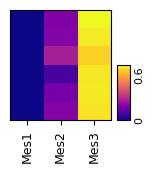

In [10]:
# signatures heatmap
fs1, fs2, var = 9, 8, list(labels_dict.keys())
hm = sc.pl.heatmap(adata, var, 'sample',
                   cmap = 'plasma', vmin = 0,
                   figsize = (1.75, 1.5),
                   show = False)

ax_hm = hm['heatmap_ax']
ax_grp = hm['groupby_ax']
ax_cb = ax_hm.figure.axes[1]
ax_grp.set_visible(False)

pos_hm  = ax_hm.get_position()
pos_cb = ax_cb.get_position()

ax_hm.invert_yaxis()
for l in ax_hm.collections:
    l.remove()

ax_hm.set_xticklabels([labels_dict[lbl.get_text()] for
                       lbl in ax_hm.get_xticklabels()],
                       fontsize = fs1)

ax_cb.set_position([pos_cb.x0, pos_cb.y0,
                    pos_cb.width,
                    .5 * pos_cb.height])
ax_cb.set_yticks([0, .6], [0, .6], size = fs2, rotation = 90)
ax_cb.tick_params(length = 0)

fn = os.path.join(pth_fig, 'signatures.pdf')
plt.savefig(fn, bbox_inches = 'tight', dpi = 1200)

In [7]:
# save results
df = adata.obs[list(labels_dict.keys())].T
df.to_csv(os.path.join(pth_out, 'signatures.csv'))

In [8]:
adata.write(os.path.join(pth_in, 'signatures.h5ad'))